# SGD hyperparameters: batch size and learning rate

Reads `results/ablations/batch_lr.csv` (made by `ablations.py embed / evaluate / collect`). Lines are the mean over seeds,
bands the standard deviation (no bands with a single seed, as for the default `batch_lr` ablation), black dots the best learning rate for each batch size. The y-axis is the stress-1 of the final
embedding, evaluated separately after optimization.

In [1]:
import sys
sys.path.insert(0, "..")  # make the modules in code/ importable

import matplotlib.pyplot as plt
import pandas as pd

import paths
import results_io as rio
from ablations import ABLATIONS, ablation_jobs

paths.FIGURES.mkdir(exist_ok=True)
if paths.STYLE.exists():
    plt.style.use(paths.STYLE)
else:
    print(f"{paths.STYLE} not found: using matplotlib's default style. Copy your mpl_style.txt there.")

df = pd.read_csv(paths.RESULTS / "ablations" / "batch_lr.csv")

In [2]:
def n_epochs_of(dataset):
    """Number of epochs these runs used (the length of a saved training curve)."""
    job = ablation_jobs(["batch_lr"], [dataset], [0])[0]
    return len(rio.load_embedding(job.emb_path, "stress_curve"))


def sgd_params_figure(dataset, ylim=None, legend_fontsize=None):
    g = (df[df.dataset == dataset]
         .groupby(["batch_size", "lr"])["stress1_metric"].agg(["mean", "std"]).reset_index())

    fig, ax = plt.subplots(figsize=(2.5, 2), layout="constrained")
    for lr, sub in g.groupby("lr"):
        sub = sub.sort_values("batch_size")
        (line,) = ax.plot(sub.batch_size, sub["mean"], ".-", label=lr)
        ax.fill_between(sub.batch_size, sub["mean"] - sub["std"], sub["mean"] + sub["std"],
                        color=line.get_color(), alpha=.2, lw=0)

    best = g.groupby("batch_size")["mean"].min()
    ax.plot(best.index, best.values, "ko")

    ax.set_xscale("log")
    ax.set_xlabel("Batch size")
    ax.set_ylabel(f"Stress-1 after {n_epochs_of(dataset)} epochs")
    ax.legend(title="Learning rate", fontsize=legend_fontsize)
    if ylim:
        ax.set_ylim(ylim)

    for ext in ("pdf", "png"):
        fig.savefig(paths.FIGURES / f"sgd-params-{dataset}.{ext}", dpi=300)
    return fig

The y-limits were set by hand for the old numbers. They are left automatic here; pass `ylim=(lo, hi)` to fix them.

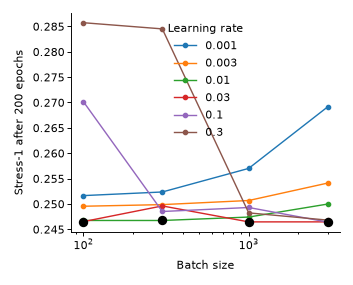

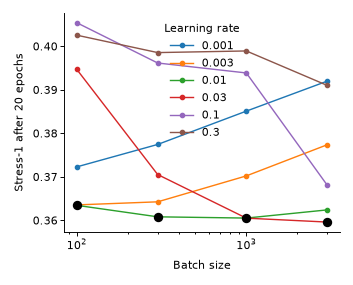

In [3]:
for dataset in ABLATIONS["batch_lr"]["datasets"]:  # tasic, mnist
    sgd_params_figure(dataset, legend_fontsize=6)